# Grating coupler

Shape the trenches of a grating coupler for a fiber.

**Question.** Light in a 220 nm silicon guide on 2 µm of buried oxide must
leave the chip into a single-mode fiber held above it, at a vacuum
wavelength of 1.55 µm. A grating of 25 shallow trenches, 70 nm deep, scatters
the guided wave upward. How much of the guide's power reaches the fiber, and
how should the period, the trench widths and the grating's position change
so that more of it does?

The page answers with one driven solve per design. The guide's
{term}`wave port` is fed 1 W, and {py:func}`gfem.beam_coupling` reads the
{term}`beam coupling` $c$, the amplitude the field couples into the
fiber's beam: by reciprocity, the wave the port would receive if the fiber
lit the grating, so $|c|^2$ is the fiber-to-chip coupling efficiency. Every fiber position and angle is read
from the same solve. The trench walls then move through
{py:func}`gfem.shape.boundary_morph`, and `jax.grad` gives the gradient of
$|c|^2$ with respect to the grating's period, fill and offset, then to
every trench's width.

**Assumptions.**

- The grating's lines are long: the problem is invariant along them, $z$.
  gfem solves it on a slab one element thick, read from a 2D
  cross-section; a 3D model holding a 10 µm wide beam is beyond a tutorial.
- The light is TE: $E$ along the lines, $z$. The slab's two faces are
  perfect electric conductors, which a field along $z$ meets at right
  angles, so they do not disturb it.
- Silicon has index 3.476 and oxide 1.444, both lossless. The substrate
  under the buried oxide is silicon.
- The fiber is a standard single-mode fiber: a Gaussian beam of waist
  $w_0 = 5.2$ µm, here coming down through the oxide at 10° from the
  normal. Its 2D, $z$-invariant version is written below.
- Absorbing faces close the section on all four sides. They are first-order
  absorbers: near-normal light leaves through them with a reflection below
  $10^{-4}$ in power.

In [1]:
import math

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from scipy.constants import c, mu_0
from scipy.optimize import minimize

import gfem
from gfem import shape

um, nm = 1e-6, 1e-9
WAVELENGTH = 1.55 * um
F0 = c / WAVELENGTH
N_SI, N_OX = 3.476, 1.444
SILICON = gfem.Material(eps_r=N_SI**2, name="silicon")
OXIDE = gfem.Material(eps_r=N_OX**2, name="oxide")
# the grating as meshed, um: period, silicon share of a period, trenches
PERIOD, FILL, TEETH = 0.63, 0.5, 25
T_SI, ETCH = 0.22, 0.07

## The section and its mesh

The section runs along the guide, $x$, from $-6$ to 19 µm, with $y$ up and
$y = 0$ at the top of the buried oxide: 0.3 µm of silicon substrate, 2 µm of
buried oxide (`"box"`), the 220 nm guide (`"si"`), and oxide cladding
(`"clad"`) up to $y = 1.8$ µm. The grating starts at $x = 0$: each period
is a silicon tooth, 315 nm, then a 70 nm deep trench of oxide (`"trench"`),
315 nm. The 50 trench sidewalls are the line `"walls"`.

The mesh is built by `tools/grating_mesh.py` (gmsh) and read from
{download}`data/grating.msh` as a slab. Its triangles are 70 nm along the
guide, growing to 280 nm in the oxide and 140 nm in the substrate. The
guide crosses both ends through the wave ports `"input"` and `"output"`,
each a window from $y = -1$ to 1 µm across the guide; the rest of the
ends, the top and the bottom absorb.

In [2]:
mesh = gfem.Mesh.from_gmsh_cross_section("data/grating.msh", length_unit="um")
model = gfem.Model(
    mesh,
    materials={
        "substrate": SILICON,
        "box": OXIDE,
        "si": SILICON,
        "trench": OXIDE,
        "clad": OXIDE,
    },
    ports=[gfem.WavePort("input", "input"), gfem.WavePort("output", "output")],
    boundaries=[
        *(gfem.Absorbing(face) for face in ("left", "right", "top", "bottom")),
        gfem.PEC("front"),
        gfem.PEC("back"),
    ],
)
thickness = mesh.section_thickness
print(f"{len(mesh.tetrahedra)} tetrahedra, slab {thickness / nm:.0f} nm thick")

25773 tetrahedra, slab 150 nm thick


## The fiber

A $z$-invariant Gaussian beam is a sum of plane waves over the directions
of the $xy$ plane. Its angular spectrum is Gaussian in the angle
$\alpha$ from the beam's axis, of width $2/(k w_0)$:

$$
E_z(x, y) = \int_{-k}^{k} A(k_x)\,
  e^{-i\left(k_x (x - x_0) - k_y (y - y_0)\right)}\,dk_x, \qquad
A = e^{-(\alpha - \alpha_0)^2 (k w_0)^2 / 4}, \quad
\alpha = \arcsin(k_x / k), \quad k_y = \sqrt{k^2 - k_x^2},
$$

a beam focused at $(x_0, y_0)$ travelling down at $\alpha_0$ from $-y$ toward
$+x$, with $k = n_\text{ox} \omega / c$. It carries
$\pi \int |A|^2 k_y\,dk_x / (\omega\mu_0)$ per unit length along $z$, and
is scaled to 1 W through the slab, as a port's mode is. It enters gfem as a
{py:obj}`gfem.IncidentField`: a function of position and frequency.

The grating sends the guided wave up and forward, toward $+x$; the fiber
that collects it points back, down and toward $-x$, so its angle is
$-10°$.

In [3]:
WAIST = 5.2 * um
ANGLE = math.radians(-10.0)


class Fiber:
    """A z-invariant TE Gaussian beam coming down through the oxide."""

    def __init__(self, x0, *, angle=ANGLE, waist=WAIST, y0=1.0 * um):
        self.x0, self.y0, self.angle, self.waist = x0, y0, angle, waist

    def __call__(self, points, frequency):
        k = 2 * np.pi * frequency / c * N_OX
        kx = np.linspace(-k, k, 401)[1:-1]
        ky = np.sqrt(k**2 - kx**2)
        a = np.exp(-((np.arcsin(kx / k) - self.angle) ** 2) * (k * self.waist) ** 2 / 4)
        dk = kx[1] - kx[0]
        omega = 2 * np.pi * frequency
        per_length = np.pi * np.sum(a**2 * ky) * dk / (omega * mu_0)  # W/m
        a *= dk / np.sqrt(per_length * mesh.section_thickness)  # 1 W through the slab
        e = np.zeros((len(points), 3), complex)
        for s in range(0, len(points), 4096):  # in blocks, to bound the memory
            x = points[s : s + 4096, :1] - self.x0
            y = points[s : s + 4096, 1:2] - self.y0
            e[s : s + 4096, 2] = np.exp(-1j * (kx * x - ky * y)) @ a
        return e


def fiber(x0, angle=ANGLE):
    return gfem.IncidentField("fiber", Fiber(x0, angle=angle))

## The grating as meshed

One solve, the input port fed 1 W at 1.55 µm. The guide's power splits
four ways: reflected into the input port, $|S_{11}|^2$, passed on to the
output port, $|S_{21}|^2$, radiated up through the cladding and down through
the buried oxide into the substrate. {py:func}`gfem.power_flow` reads the
last two as the power leaving the elements above $y = 1.3$ µm and below
$y = -1.2$ µm (the absorbing faces take it).

In [4]:
problem = gfem.Driven(F0, excite="input", keep_fields=True)
options = gfem.SolverOptions(order=2, linear_solver="direct")


def split(result, on):
    # the shares of the guide's 1 W: reflected, passed on, up and down
    field = result.e_field(F0, "input")
    s = result.s

    def leaving(inside):
        return -float(gfem.power_flow(field, inside, model=on))

    up = leaving(lambda x: x[:, 1] > 1.3 * um)
    down = leaving(lambda x: x[:, 1] < -1.2 * um)
    return {
        "reflected": abs(complex(s["input", "input"][0])) ** 2,
        "passed on": abs(complex(s["output", "input"][0])) ** 2,
        "up": up,
        "down": down,
    }


initial = gfem.solve(model, problem, options=options)
shares = split(initial, model)
for name, value in shares.items():
    print(f"{name:10s} {value:.4f}")
print(f"sum        {sum(shares.values()):.12f}")

reflected  0.0022
passed on  0.0220
up         0.6565
down       0.3186
sum        0.999315362632


Two thirds of the power go up, a third down into the substrate, 2 % passes
the grating and 0.2 % is reflected. The four shares add up to the 1 W fed
within $7 \times 10^{-4}$, the light that leaves through the absorbing ends
between the two planes: the trust section returns to this balance.

## Where to put the fiber

The coupling into the fiber is a post-processing of the solved field, so
every fiber position and angle comes from the solve above. A scan of the
focus along $x$ at $-10°$, then of the angle at the best position:

In [5]:
def efficiency(result, on, beam):
    return float(abs(gfem.beam_coupling(result, "input", beam, model=on)[0]) ** 2)


positions = np.arange(1.5, 8.6, 1.0) * um
along = [efficiency(initial, model, fiber(x0)) for x0 in positions]
X_FIBER = float(positions[int(np.argmax(along))])
angles = np.radians([-16, -13, -10, -7, -4])
tilt = [efficiency(initial, model, fiber(X_FIBER, a)) for a in angles]
print("focus (um)  " + "  ".join(f"{x / um:5.1f}" for x in positions))
print("efficiency  " + "  ".join(f"{e:5.3f}" for e in along))
print("angle (deg) " + "  ".join(f"{np.degrees(a):5.0f}" for a in angles))
print("efficiency  " + "  ".join(f"{e:5.3f}" for e in tilt))
FIBER = fiber(X_FIBER)
history_initial = max(along)

focus (um)    1.5    2.5    3.5    4.5    5.5    6.5    7.5    8.5
efficiency  0.379  0.463  0.518  0.534  0.514  0.465  0.401  0.332
angle (deg)   -16    -13    -10     -7     -4
efficiency  0.041  0.216  0.534  0.376  0.079


The best focus sits about 4.5 µm into the 15.75 µm long grating: the
guided wave decays along it, and the beam sits where the light leaves.
Half the guide's power couples into the fiber at 1.55 µm, against the two
thirds that go up: the rest goes up with the wrong shape, an exponential
tail rather than a Gaussian. The fiber is now fixed there, at $-10°$, and
the grating moves to match it.

## The shape design

`boundary_morph` moves the 50 sidewalls, line `"walls"`, along their
normals. Each sidewall node is one parameter $t_i$; with `grows="si"`,
$t_i > 0$ moves the wall into the trench, so the silicon tooth grows. Every
other named line holds or slides, and the elements touching the absorbing
faces stay where they were imported, so the layer `beam_coupling` reads
the fiber on keeps its geometry.

A grating is stated by a few numbers. Trench $i$ spans
$x_0 + i\Lambda + f_i\Lambda < x < x_0 + (i + 1)\Lambda$ for a period
$\Lambda$, a fill $f_i$ (the silicon share of the period) and an offset
$x_0$. The map below turns them into the walls' displacements: the
displacement of a wall node is the change of its wall's $x$ times the
$x$ component of its normal.

In [6]:
morph = shape.boundary_morph(model, "walls", grows="si")
x_wall = morph.points[:, 0] / um
normal_x = morph.normals[:, 0]
number = np.floor(x_wall / PERIOD + 1e-6).astype(int)
closing = np.isclose(x_wall, number * PERIOD, atol=1e-6)  # a trench's right wall
trench = np.where(closing, number - 1, number)
print(f"{morph.n_params} wall nodes, trenches {trench.min()} to {trench.max()}")


def walls(period, fills, offset):
    # period (um), the 25 fills, offset (um) -> each wall node's displacement (m)
    fills = jnp.broadcast_to(fills, (TEETH,))
    start = offset + trench * period
    moved = jnp.where(closing, start + period, start + fills[trench] * period)
    return (moved - x_wall) * um * normal_x


def designed(period, fills, offset):
    return model.replace(mesh=morph(walls(period, fills, offset)))


def coupling(period, fills, offset):
    on = designed(period, fills, offset)
    result = gfem.solve(on, problem, options=options)
    return jnp.abs(gfem.beam_coupling(result, "input", FIBER, model=on)[0]) ** 2

200 wall nodes, trenches 0 to 24


### Period, fill and offset

Three parameters, scaled so that one unit is a sizeable change: 10 nm of
period, 5 % of fill, 0.5 µm of offset. L-BFGS-B, bounded, maximizes $|c|^2$;
each step is one solve and its adjoint, the gradient through the morph
and the solve. The bounds keep the walls' moves within the mesh's reach:
with the period free by 30 nm, the last trench moves by up to 0.75 µm.

In [7]:
SCALE = np.array([0.01, 0.05, 0.5])


def uniform(u):
    period, fill, offset = jnp.array([PERIOD, FILL, 0.0]) + u * SCALE
    return period, fill, offset


uniform_value_and_grad = jax.value_and_grad(lambda u: -coupling(*uniform(u)))
history, evaluated = [], {}


def objective(u, value_and_grad=uniform_value_and_grad):
    value, gradient = value_and_grad(jnp.asarray(u))
    history.append(-float(value))
    evaluated[tuple(u)] = np.asarray(gradient, dtype=float)
    return float(value), evaluated[tuple(u)]


found = minimize(
    objective,
    np.zeros(3),
    jac=True,
    method="L-BFGS-B",
    bounds=[(-3, 3), (-4, 4), (-2, 2)],
    options={"maxiter": 3},
)
uniform_best = -float(found.fun)
best_uniform = np.asarray(uniform(jnp.asarray(found.x)), dtype=float)
uniform_history = list(history)
print(f"{len(history)} solves: |c|^2 " + " ".join(f"{h:.3f}" for h in history))
print(
    f"period {best_uniform[0] * 1e3:.1f} nm, fill {best_uniform[1]:.3f}, "
    f"offset {best_uniform[2] * 1e3:.0f} nm"
)

4 solves: |c|^2 0.534 0.541 0.555 0.555
period 634.2 nm, fill 0.512, offset 5 nm


### Every trench's width: apodization

A uniform grating radiates an exponentially decaying profile, which
matches a Gaussian beam at best to about 80 %. Letting each tooth's fill
change on its own shapes the profile: 25 fills, at the period and offset
just found, at the cost of the same one adjoint per step.

In [8]:
def apodized(u):
    return best_uniform[0], best_uniform[1] + u * 0.05, best_uniform[2]


apodized_value_and_grad = jax.value_and_grad(lambda v: -coupling(*apodized(v)))
history = []
found = minimize(
    lambda u: objective(u, apodized_value_and_grad),
    np.zeros(TEETH),
    jac=True,
    method="L-BFGS-B",
    bounds=[(-4, 4)] * TEETH,
    options={"maxiter": 5},
)
fills = np.asarray(apodized(found.x)[1], dtype=float)
apodized_history = list(history)
print(f"{len(history)} solves: |c|^2 " + " ".join(f"{h:.3f}" for h in history))
print("fills " + " ".join(f"{f:.2f}" for f in fills))
u_apodized = found.x
apodized_best = -float(found.fun)

7 solves: |c|^2 0.555 0.555 0.580 0.580 0.581 0.581 0.581
fills 0.38 0.36 0.44 0.41 0.45 0.50 0.54 0.52 0.51 0.53 0.54 0.54 0.53 0.53 0.54 0.53 0.54 0.52 0.52 0.52 0.52 0.52 0.51 0.51 0.51


The uniform grating's three numbers move little: the period grows by 4 nm,
the fill from 0.50 to 0.51 and the offset by 5 nm, and $|c|^2$ rises from
0.534 to 0.555 in four solves. The fiber was placed on the meshed grating,
so the offset has little to gain. Freeing each tooth adds more, to 0.581
in seven solves: the first five teeth get narrower, fills of 0.36 to 0.45,
so the grating scatters weakly where the fiber's beam starts and strongly
further on, and the radiated profile rises like the beam's instead of
starting at its peak.

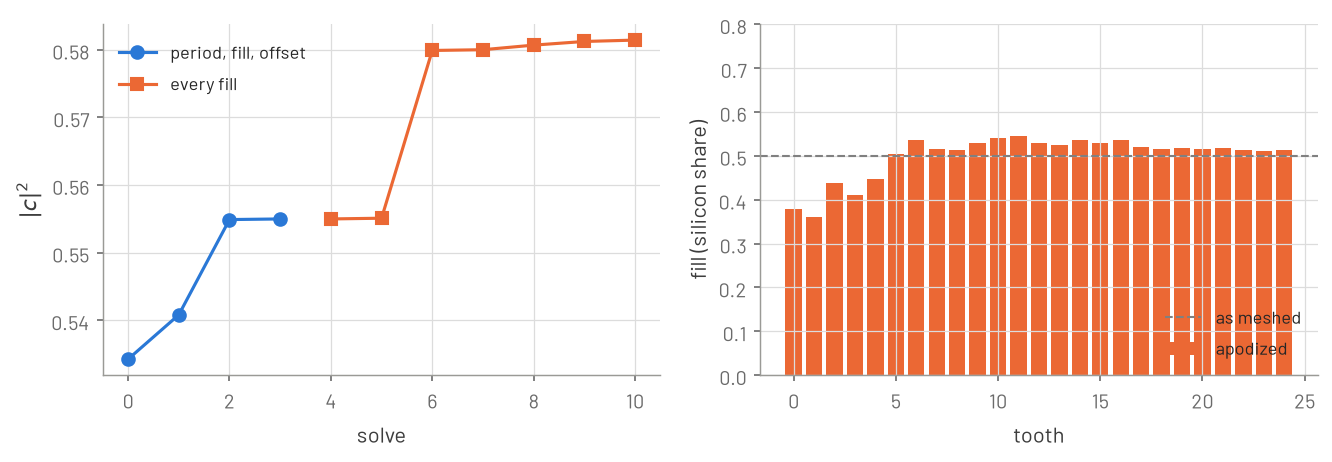

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.2))
n = len(uniform_history)
left.plot(range(n), uniform_history, "o-", label="period, fill, offset")
left.plot(
    range(n, n + len(apodized_history)), apodized_history, "s-", label="every fill"
)
left.set(xlabel="solve", ylabel="$|c|^2$")
left.legend(fontsize="small")
right.bar(np.arange(TEETH), fills, color="C1", label="apodized")
right.axhline(FILL, color="gray", ls="--", lw=1, label="as meshed")
right.set(xlabel="tooth", ylabel="fill (silicon share)", ylim=(0, 0.8))
right.legend(fontsize="small", loc="lower right")
fig.tight_layout();

## The designed grating

The apodized grating over a band, 1.50 to 1.60 µm, in one driven problem
with five frequencies: the field of each is coupled into the same fiber,
and the shares of the guide's power at 1.55 µm are those of the first
solve, for comparison.

In [10]:
design = designed(*apodized(jnp.asarray(u_apodized)))
WAVELENGTHS = np.linspace(1.50, 1.60, 5) * um
band = gfem.solve(
    design,
    gfem.Driven(tuple(c / WAVELENGTHS), excite="input", keep_fields=True),
    options=options,
)
coupled = gfem.beam_coupling(band, "input", FIBER, model=design)
spectrum = np.abs(np.asarray(coupled)) ** 2
print("wavelength (um) " + "  ".join(f"{w / um:5.3f}" for w in WAVELENGTHS))
print("efficiency      " + "  ".join(f"{e:5.3f}" for e in spectrum))
final = gfem.solve(design, problem, options=options)
final_shares = split(final, design)
for name, value in final_shares.items():
    print(f"{name:10s} {shares[name]:.4f} -> {value:.4f}")

wavelength (um) 1.500  1.525  1.550  1.575  1.600
efficiency      0.147  0.392  0.581  0.460  0.195


reflected  0.0022 -> 0.0006
passed on  0.0220 -> 0.0226
up         0.6565 -> 0.6567
down       0.3186 -> 0.3196


At 1.55 µm the coupling is 0.581. It falls by 1 dB, to 0.46, about 25 nm
above and sooner below, and to 0.15 and 0.20 at the band's ends: a grating
coupler is a narrow-band device. The shares of the guide's power barely
move: 0.657 goes up before and after the design, which changed the shape
of that light, not its amount. The reflection falls from 0.22 % to
0.06 %.

The field of the designed grating, $|E_z|$, in the section: the guided wave
enters from the left, the grating sends a tilted beam up through the
cladding and a weaker one down, which the substrate takes.

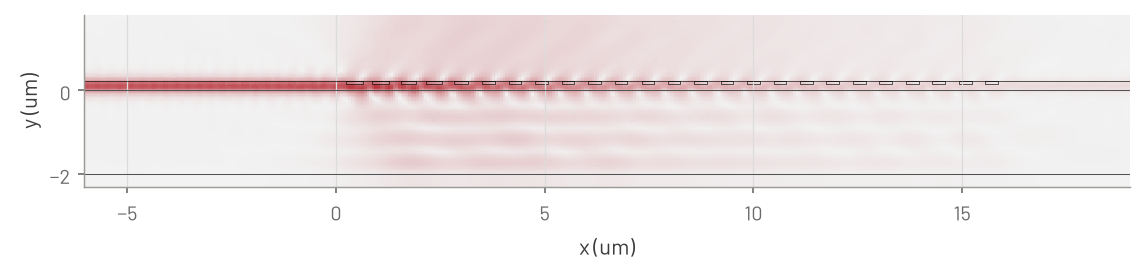

In [11]:
xs = np.linspace(-6, 19, 400) * um
ys = np.linspace(-2.3, 1.8, 130) * um
grid = np.stack(np.meshgrid(xs, ys), axis=-1).reshape(-1, 2)
points = np.c_[grid, np.full(len(grid), mesh.section_thickness / 2)]
field = final.e_field(F0, "input")
ez = np.abs(np.asarray(field.at(points))[:, 2]).reshape(len(ys), len(xs))
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.pcolormesh(xs / um, ys / um, ez, shading="auto", cmap="gfem_sensitivity")
for a, b in zip(
    np.asarray(apodized(jnp.asarray(u_apodized))[2])
    + np.arange(TEETH) * best_uniform[0]
    + fills * best_uniform[0],
    np.asarray(apodized(jnp.asarray(u_apodized))[2])
    + np.arange(1, TEETH + 1) * best_uniform[0],
    strict=True,
):
    ax.add_patch(Rectangle((a, T_SI - ETCH), b - a, ETCH, fc="none", ec="k", lw=0.3))
for y in (-2, 0, T_SI):  # the box, the guide
    ax.axhline(y, color="k", lw=0.3)
ax.set(xlabel="x (um)", ylabel="y (um)", aspect="equal");

## Trust

**The gradient.** The optimizer trusts the adjoint gradient through the
morph, the solve and the coupling. Along a random direction of the 25
fills, at the apodized design, it is compared with a central finite
difference of two more solves.

In [12]:
direction = np.random.default_rng(0).standard_normal(TEETH)
direction /= np.linalg.norm(direction)
STEP = 1e-3  # in units of 5 % of fill: 50 ppm of fill
adjoint = -float(evaluated[tuple(u_apodized)] @ direction)
plus, minus = (
    float(coupling(*apodized(jnp.asarray(u_apodized + s * STEP * direction))))
    for s in (1, -1)
)
difference = (plus - minus) / (2 * STEP)
gradient_error = abs(adjoint - difference) / abs(difference)
print(f"adjoint {adjoint:.6e}, finite difference {difference:.6e}")
print(f"relative difference {gradient_error:.1e}")

adjoint 6.982106e-06, finite difference 6.982003e-06
relative difference 1.5e-05


They agree to about $10^{-5}$, on the mesh the tutorial designs on.

**Power balance.** The guide's watt must go somewhere: the four shares of
the designed grating add up to

In [13]:
balance = abs(sum(final_shares.values()) - 1)
print(f"|reflected + passed on + up + down - 1| = {balance:.1e}")
print(f"coupled {spectrum[2]:.4f} of the {final_shares['up']:.4f} going up")

|reflected + passed on + up + down - 1| = 5.4e-04
coupled 0.5814 of the 0.6567 going up


$5.4 \times 10^{-4}$ short of 1: the light that leaves through the
absorbing ends between the two planes, beside the ports, which no share
counts. And the fiber takes less than what goes up, as it must: 0.581 of
0.657.

**Forward against reciprocal.** The coupling's claim is reciprocity: the
port-fed field's coupling into the fiber equals the wave the port
receives when the fiber lights the grating. The page checks it with the
beam-lit solve, which needs the fiber to be a solution of Maxwell's
equations in a uniform background ({doc}`../recipes/incident-fields`):
here the substrate is made of oxide, so the background is the oxide and
only the guide scatters, and the fiber is narrowed to a 2.5 µm waist so
that it stays clear of the ports at the ends. One solve gives both: the
port's column and the fiber's.

The same solve checks that the coupling does not depend on where it is
read: `beam_coupling` reads it on the elements just above the side's
surface, by default the top face, and a side bounded by the plane
$y = 1.3$ or 1.5 µm gives the same number.

In [14]:
narrow = gfem.IncidentField("fiber", Fiber(X_FIBER, waist=2.5 * um))
uniform_oxide = model.with_material("substrate", OXIDE).replace(background=OXIDE)
both = gfem.solve(
    uniform_oxide,
    gfem.Driven(F0, excite="input", sources=narrow, keep_fields=True),
    options=options,
)
forward = complex(gfem.beam_coupling(both, "input", narrow, model=uniform_oxide)[0])
reciprocal = complex(both.port_wave("input", "fiber")[0])
reciprocity = abs(forward - reciprocal) / abs(reciprocal)
print(f"forward    {forward:.4f}")
print(f"reciprocal {reciprocal:.4f}")
print(f"relative difference {reciprocity:.1e}")
planes = 0.0
for height in (1.3, 1.5):
    below = lambda x, h=height: x[:, 1] < h * um  # noqa: E731
    on_plane = complex(
        gfem.beam_coupling(both, "input", narrow, model=uniform_oxide, side=below)[0]
    )
    planes = max(planes, abs(on_plane - forward) / abs(forward))
print(f"largest difference between planes {planes:.1e}")

forward    0.3926+0.3037j
reciprocal 0.3950+0.3070j
relative difference 8.2e-03


largest difference between planes 2.3e-03


The two routes agree to $8.2 \times 10^{-3}$. What is left is mostly the
absorbing top face: the beam-lit solve sends the fiber's beam in through
it, and a first-order absorber reflects a beam 10° off its normal by
about 0.8 % in amplitude, which the port-fed route does not see. The
planes agree to $2.3 \times 10^{-3}$.

## Limits

- **A 2D grating.** The lines are infinitely long and the fiber's beam is
  a 2D one: a 3D fiber mode over a finite grating couples somewhat less.
- **A local optimum.** The optimizer runs a few steps from the meshed
  grating, within bounds the mesh allows; a different start, or more
  steps, may find more. The etch depth, the buried oxide's thickness and
  a bottom mirror, which set much of the efficiency, are fixed here.
- **One mesh.** The walls move on the imported mesh; changes of the period
  that move the last trenches by more than a few elements need a new
  mesh, as does a finer one for converged numbers.
- **First-order absorbers.** They reflect near-normal light weakly, below
  $10^{-4}$ of its power, and light at grazing angles strongly.

## Next

- {doc}`shape`: a shape design of a coplanar line, with a mesh-quality
  check at each step.
- {doc}`../recipes/incident-fields`: incident fields, Gaussian beams and
  the beam-lit solve.
- {py:mod}`gfem.conventions`: port waves and beam coupling, their units
  and phases.

The numbers this page relies on, checked: the design gains more than 0.02
over the grating as meshed, the gradient meets the finite difference to
1e-3, the power balance closes to 2e-3, forward meets reciprocal to 2e-2
and the planes agree to 1e-2.

In [15]:
gain = apodized_best - history_initial
np.testing.assert_array_less(0.02, gain)
np.testing.assert_array_less(gradient_error, 1e-3)
np.testing.assert_array_less(balance, 2e-3)
np.testing.assert_array_less(reciprocity, 2e-2)
np.testing.assert_array_less(planes, 1e-2)